In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/bank-direct-marketing-campaigns.csv')

In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  campaign        41188 non-null  int64  
 11  pdays           41188 non-null  int64  
 12  previous        41188 non-null  int64  
 13  poutcome        41188 non-null  object 
 14  emp.var.rate    41188 non-null  float64
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null 

In [5]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [6]:
df['y'] = df['y'].map({'no': 0, 'yes': 1})

In [7]:
df['y'].value_counts()

y
0    36548
1     4640
Name: count, dtype: int64

<Axes: xlabel='y', ylabel='count'>

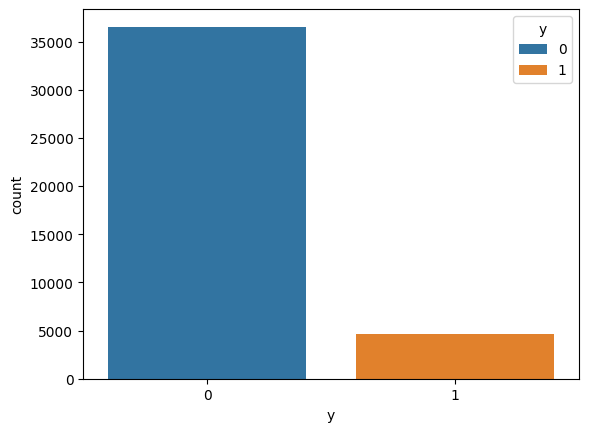

In [8]:
sns.countplot(data=df, x='y', hue='y')

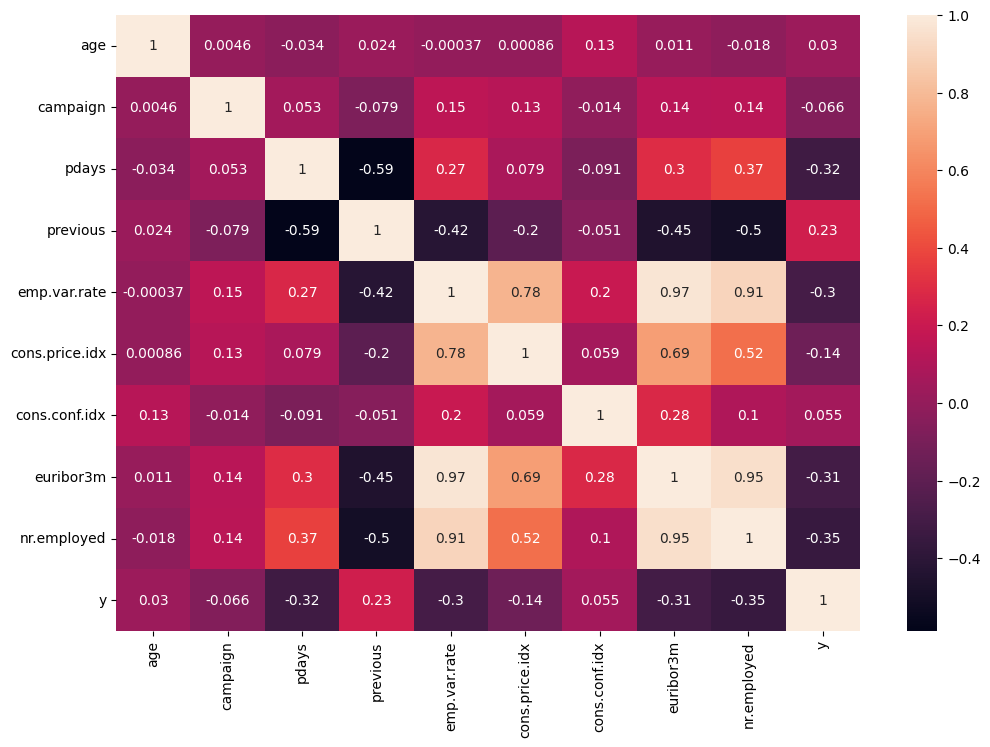

In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True);

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest

In [11]:
X = df.drop('y', axis=1)

In [12]:
y = df['y']

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104)

In [15]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

In [16]:
iso_forest = IsolationForest(contamination=0.01, n_estimators=100, n_jobs=-1, random_state=104)

In [18]:
mask = iso_forest.fit_predict(X_train[num_features])

In [19]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [20]:
X_train.shape

(32950, 19)

In [21]:
X_train_cleaned.shape

(32620, 19)

In [22]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler_2', StandardScaler())
])

In [23]:
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [24]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ],
    remainder='passthrough'
)

In [66]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegressionCV(Cs=10, cv=7, penalty='l2', solver='lbfgs',
                                   max_iter=500, n_jobs=-1, class_weight='balanced', random_state=104))
])

In [67]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [98]:
%%time
pipe.fit(X_train_cleaned, y_train_cleaned)

CPU times: total: 547 ms
Wall time: 6.26 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [99]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [100]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [2.7825594]


In [101]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [102]:
accuracy

0.8194950230638505

In [103]:
recall

0.6537634408602151

In [104]:
precision

0.34292160180485054

In [105]:
roc_auc_train

0.8025431690886096

In [106]:
roc_auc_test

0.7967984709642106

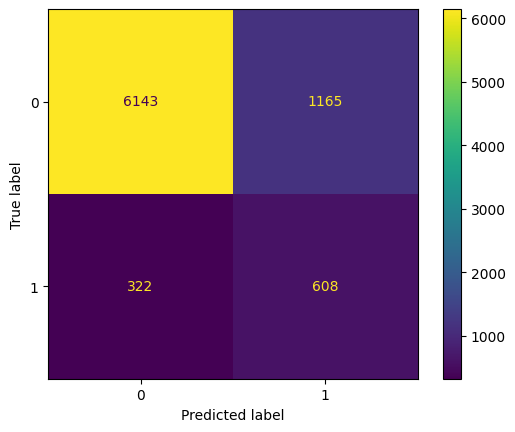

In [107]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test);

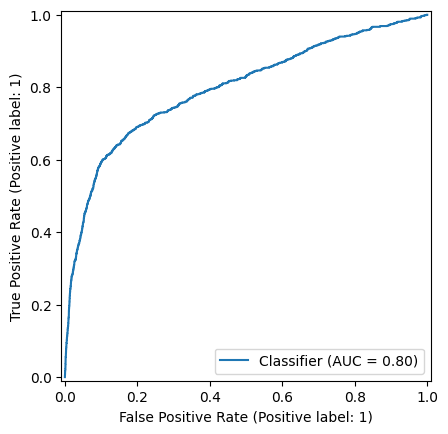

In [109]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba);

In [110]:
%%time
pipe.fit(X, y)

CPU times: total: 734 ms
Wall time: 28.7 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [111]:
y_full_pred = pipe.predict_proba(X)[:, 1]

In [112]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")

Лучшее значение C: [0.0001]


In [113]:
roc_auc_full = roc_auc_score(y, y_full_pred)

In [114]:
roc_auc_full

0.7876335395493126

In [128]:
custom_bank_df = pd.DataFrame([
    {
        'age': 22,
        'job': 'services',
        'marital': 'single',
        'education': 'high.school',
        'default': 'yes',
        'housing': 'yes',
        'loan': 'yes',
        'contact': 'cellular',
        'month': 'may',
        'day_of_week': 'mon',
        'campaign': 6,
        'pdays': 999,
        'previous': 0,
        'poutcome': 'nonexistent',
        'emp.var.rate': 1.4,
        'cons.price.idx': 93.994,
        'cons.conf.idx': -36.4,
        'euribor3m': 4.857,
        'nr.employed': 5191.0
    },
    {
        'age': 65,
        'job': 'retired',
        'marital': 'married',
        'education': 'university.degree',
        'default': 'no',
        'housing': 'no',
        'loan': 'no',
        'contact': 'cellular',
        'month': 'oct',
        'day_of_week': 'thu',
        'campaign': 1,
        'pdays': 10,
        'previous': 2,
        'poutcome': 'success',
        'emp.var.rate': -1.8,
        'cons.price.idx': 92.893,
        'cons.conf.idx': -46.2,
        'euribor3m': 1.327,
        'nr.employed': 5099.1
    }
])

In [129]:
custom_bank_df = custom_bank_df[X_train_cleaned.columns]

In [130]:
custom_bank_df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,22,services,single,high.school,yes,yes,yes,cellular,may,mon,6,999,0,nonexistent,1.4,93.994,-36.4,4.857,5191.0
1,65,retired,married,university.degree,no,no,no,cellular,oct,thu,1,10,2,success,-1.8,92.893,-46.2,1.327,5099.1


In [131]:
preds = pipe.predict(custom_bank_df)
preds_proba = pipe.predict_proba(custom_bank_df)

In [132]:
classes_map = {
    0: "ОТКАЗ (Клиент не откроет депозит) 🔴",
    1: "СОГЛАСИЕ (Успешное оформление вклада!) 🟢"
}

expected_list = [
    "МОЛОДОЙ КЛИЕНТ С КРЕДИТАМИ, КРАЙНЕ КОРОТКИЙ ЗВОНОК В МАЕ",
    "ПЕНСИОНЕР С ВЫСШИМ ОБРАЗОВАНИЕМ, УСПЕШНАЯ ИСТОРИЯ КОНТАКТОВ"
]

print("=" * 90)
print("🏦  ДЕПЛОЙ СИСТЕМЫ АНАЛИЗА ЭФФЕКТИВНОСТИ МАРКЕТИНГОВЫХ КАМПАНИЙ БАНКА")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n📞 АНКЕТА ТЕЛЕМАРКЕТИНГА №{idx + 1}:")
    print(f" -> Профиль анкеты:     {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:  {classes_map[class_out]}")
    print(f" -> Уверенность логита: {prob:.2f}% 📊")
    print("-" * 90)

🏦  ДЕПЛОЙ СИСТЕМЫ АНАЛИЗА ЭФФЕКТИВНОСТИ МАРКЕТИНГОВЫХ КАМПАНИЙ БАНКА

📞 АНКЕТА ТЕЛЕМАРКЕТИНГА №1:
 -> Профиль анкеты:     МОЛОДОЙ КЛИЕНТ С КРЕДИТАМИ, КРАЙНЕ КОРОТКИЙ ЗВОНОК В МАЕ
 -> Вердикт ИИ-модели:  ОТКАЗ (Клиент не откроет депозит) 🔴
 -> Уверенность логита: 69.75% 📊
------------------------------------------------------------------------------------------

📞 АНКЕТА ТЕЛЕМАРКЕТИНГА №2:
 -> Профиль анкеты:     ПЕНСИОНЕР С ВЫСШИМ ОБРАЗОВАНИЕМ, УСПЕШНАЯ ИСТОРИЯ КОНТАКТОВ
 -> Вердикт ИИ-модели:  СОГЛАСИЕ (Успешное оформление вклада!) 🟢
 -> Уверенность логита: 81.35% 📊
------------------------------------------------------------------------------------------


In [133]:
class_percents = df['y'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 88.7%, 1: 11.3%


In [134]:
import json
import os

advanced_report = {
    "project": "Bank Marketing Deposit Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-08',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [135]:
from joblib import dump, load

In [136]:
os.makedirs('model', exist_ok=True)

In [137]:
dump(pipe, "model/bank_marketing_deposit_predict_logistic_regression_cv_2026_v1.pkl")

['model/bank_marketing_deposit_predict_logistic_regression_cv_2026_v1.pkl']

In [138]:
loaded_pipe = load("model/bank_marketing_deposit_predict_logistic_regression_cv_2026_v1.pkl")

In [139]:
preds = loaded_pipe.predict(custom_bank_df)
preds_proba = loaded_pipe.predict_proba(custom_bank_df)

In [140]:
classes_map = {
    0: "ОТКАЗ (Клиент не откроет депозит) 🔴",
    1: "СОГЛАСИЕ (Успешное оформление вклада!) 🟢"
}

expected_list = [
    "МОЛОДОЙ КЛИЕНТ С КРЕДИТАМИ, КРАЙНЕ КОРОТКИЙ ЗВОНОК В МАЕ",
    "ПЕНСИОНЕР С ВЫСШИМ ОБРАЗОВАНИЕМ, УСПЕШНАЯ ИСТОРИЯ КОНТАКТОВ"
]

print("=" * 90)
print("🏦  ДЕПЛОЙ СИСТЕМЫ АНАЛИЗА ЭФФЕКТИВНОСТИ МАРКЕТИНГОВЫХ КАМПАНИЙ БАНКА")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n📞 АНКЕТА ТЕЛЕМАРКЕТИНГА №{idx + 1}:")
    print(f" -> Профиль анкеты:     {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:  {classes_map[class_out]}")
    print(f" -> Уверенность логита: {prob:.2f}% 📊")
    print("-" * 90)

🏦  ДЕПЛОЙ СИСТЕМЫ АНАЛИЗА ЭФФЕКТИВНОСТИ МАРКЕТИНГОВЫХ КАМПАНИЙ БАНКА

📞 АНКЕТА ТЕЛЕМАРКЕТИНГА №1:
 -> Профиль анкеты:     МОЛОДОЙ КЛИЕНТ С КРЕДИТАМИ, КРАЙНЕ КОРОТКИЙ ЗВОНОК В МАЕ
 -> Вердикт ИИ-модели:  ОТКАЗ (Клиент не откроет депозит) 🔴
 -> Уверенность логита: 69.75% 📊
------------------------------------------------------------------------------------------

📞 АНКЕТА ТЕЛЕМАРКЕТИНГА №2:
 -> Профиль анкеты:     ПЕНСИОНЕР С ВЫСШИМ ОБРАЗОВАНИЕМ, УСПЕШНАЯ ИСТОРИЯ КОНТАКТОВ
 -> Вердикт ИИ-модели:  СОГЛАСИЕ (Успешное оформление вклада!) 🟢
 -> Уверенность логита: 81.35% 📊
------------------------------------------------------------------------------------------
